# FER2013 emotion exploratory data analysis

Explore the downloaded emotion dataset before designing a training pipeline: class balance, example faces,
image integrity and pixel properties, duplicate leakage, conflicting labels, and implications for evaluation.
This notebook describes the data; it does not train a model, remove images, or create a validation split.

**Source:** [FER-2013 by Manas Sambare on Kaggle](https://www.kaggle.com/datasets/msambare/fer2013), version 1.
Kaggle API metadata checked on 2026-11-05 lists **Database: Open Database, Contents: Database Contents**.
This records the distributor's license metadata rather than establishing rights for every underlying face image.
The source description mentions 3,589 public-test images; inspect the actual downloaded splits below rather
than assuming original public/private membership.

## Run and storage

Select the project's **Python 3.13.x** environment with its existing NumPy, Pillow and Matplotlib dependencies.
No GPU, Torch import, Kaggle credentials or network access is needed. Run from the repository or any child folder.
For a different working directory, set `REPO_ROOT_OVERRIDE` in the next cell. Dataset paths use the repository's
`load_paths` function and `configs/project.toml`; set `DATA_ROOT_OVERRIDE` only for external extracted storage.

The full audit reads every image once and can take several minutes. Small JSON/CSV summaries and aggregate
plots go to a new run directory under `reports/emotion/`. Per-image inventories, duplicate membership and any
local review decisions go under ignored `data/emotion_eda/`. Raw face samples display only in memory.
Clear notebook outputs before committing; do not commit images embedded in notebook outputs.


In [1]:
from pathlib import Path
import sys, json, csv, hashlib, io, platform
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

REPO_ROOT_OVERRIDE = None  # e.g. Path('/content/facial-attendance')
CONFIG_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
SEED = 42
WORKERS = 8
if sys.version_info[:2] != (3, 13):
    raise RuntimeError('Select the project Python 3.13.x kernel; see docs/setup.md.')

def find_repo(start):
    for candidate in (start, *start.parents):
        if (candidate / 'configs/project.toml').is_file() and (candidate / 'src/facial_attendance').is_dir():
            return candidate
    raise FileNotFoundError('Set REPO_ROOT_OVERRIDE to the repository checkout.')

ROOT = find_repo(Path(REPO_ROOT_OVERRIDE or Path.cwd()).expanduser().resolve())
sys.path.insert(0, str(ROOT / 'src'))
from facial_attendance.config import load_paths
CONFIG = Path(CONFIG_OVERRIDE) if CONFIG_OVERRIDE else ROOT / 'configs/project.toml'
if not CONFIG.is_absolute():
    CONFIG = ROOT / CONFIG
paths = load_paths(CONFIG, root=ROOT)
DATA = (ROOT / Path(DATA_ROOT_OVERRIDE)).resolve() if DATA_ROOT_OVERRIDE else paths.emotion_data
assert DATA.is_dir(), f'Extract FER2013 at the configured emotion_data path: {DATA}'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
REPORT = ROOT / 'reports/emotion' / RUN_ID
LOCAL = ROOT / 'data/emotion_eda' / RUN_ID
REPORT.mkdir(parents=True, exist_ok=False)
LOCAL.mkdir(parents=True, exist_ok=False)
print('Python:', platform.python_version(), '| dataset:', DATA)
print('Aggregate reports:', REPORT.relative_to(ROOT))


Python: 3.13.9 | dataset: C:\facial-attendance\data\raw\emotion
Aggregate reports: reports\emotion\20261105T163647409557Z


## 1. Inventory and the label contract

The selected model order follows the source IDs. Folder loaders often assign alphabetical IDs;
that puts neutral at 4 instead of 6. The table below makes the required remapping explicit.
Unexpected folders are rejected rather than silently assigned new labels. Counts are measured from disk.


In [2]:
LABELS = ('angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral')
CLASS_TO_ID = {label: i for i, label in enumerate(LABELS)}
SPLITS = ('train', 'test')
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
files, ignored = [], []
for split in SPLITS:
    folder = DATA / split
    if not folder.is_dir():
        raise FileNotFoundError(folder)
    observed = {p.name for p in folder.iterdir() if p.is_dir()}
    if observed != set(LABELS):
        raise ValueError(f'{split}: missing={set(LABELS)-observed}, unexpected={observed-set(LABELS)}')
    for label in LABELS:
        for path in sorted((folder / label).rglob('*')):
            if not path.is_file():
                continue
            if not path.resolve().is_relative_to((folder / label).resolve()):
                raise ValueError('A dataset symlink escapes its class folder.')
            (files if path.suffix.lower() in EXTENSIONS else ignored).append(path)
counts = {s: {label: sum(p.relative_to(DATA).parts[:2] == (s, label) for p in files)
              for label in LABELS} for s in SPLITS}
print(f"{'Folder':12s} {'Model ID':>8s} {'Alphabetical ID':>16s} {'Train':>8s} {'Test':>8s}")
for label in LABELS:
    print(f'{label:12s} {CLASS_TO_ID[label]:8d} {sorted(LABELS).index(label):16d} '
          f"{counts['train'][label]:8d} {counts['test'][label]:8d}")
print('Totals:', {s: sum(counts[s].values()) for s in SPLITS}, '| non-image files:', len(ignored))


Folder       Model ID  Alphabetical ID    Train     Test
angry               0                0     3995      958
disgust             1                1      436      111
fear                2                2     4097     1024
happy               3                3     7215     1774
sad                 4                5     4830     1247
surprise            5                6     3171      831
neutral             6                4     4965     1233
Totals: {'train': 28709, 'test': 7178} | non-image files: 0


## 2. Class balance and split composition

Absolute counts show support; percentages compare composition without letting split size dominate.
Rare-class performance needs per-class recall/F1 and macro-F1 alongside accuracy. Any weighting or sampling
must be fitted to the eventual training subset, not the test set.


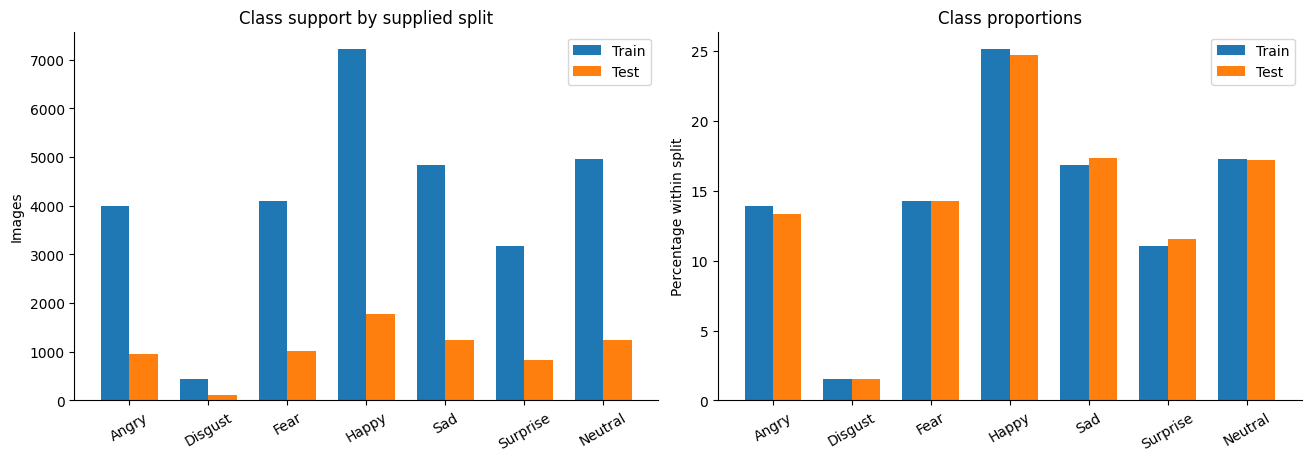

Largest / smallest training class: 16.55


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
x = np.arange(len(LABELS))
for i, split in enumerate(SPLITS):
    values = np.array([counts[split][label] for label in LABELS])
    axes[0].bar(x + (i-.5)*.36, values, .36, label=split.title())
    axes[1].bar(x + (i-.5)*.36, 100*values/values.sum(), .36, label=split.title())
for ax in axes:
    ax.set_xticks(x, [label.title() for label in LABELS], rotation=30)
    ax.legend(); ax.spines[['top', 'right']].set_visible(False)
axes[0].set(ylabel='Images', title='Class support by supplied split')
axes[1].set(ylabel='Percentage within split', title='Class proportions')
fig.savefig(REPORT / 'class_distribution.png', dpi=160)
plt.show()
train_support = counts['train']
print('Largest / smallest training class:', round(max(train_support.values()) / min(train_support.values()), 2))


## 3. Reproducible training examples

Three training images per class are sampled with seed 42. Look for ambiguity, occlusions, pose and crop
variation. Folder labels are annotations, not independently verified emotional states. Test examples are
not used to select transformations. This cell intentionally does not save face-image figures.

Face previews are omitted from the published outputs to keep face images local. Run the following cell locally to view them.


In [4]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(LABELS), 3, figsize=(8, 15), layout='constrained')
for row, label in enumerate(LABELS):
    candidates = [p for p in files if p.relative_to(DATA).parts[:2] == ('train', label)]
    for col, index in enumerate(rng.choice(len(candidates), size=min(3,len(candidates)), replace=False)):
        p = candidates[int(index)]
        try:
            with Image.open(p) as image:
                axes[row,col].imshow(image.convert('L'), cmap='gray', vmin=0, vmax=255)
        except Exception as exc:
            axes[row,col].text(.1,.5, type(exc).__name__)
        axes[row,col].set_title(label.title(), fontsize=10)
for ax in axes.flat:
    ax.axis('off')
plt.show()


## 4. Full image-integrity and content audit

Decode every candidate image on CPU. Measure original size/mode, grayscale mean and contrast, and
near-black/near-white pixel fractions. Raw-file SHA-256 detects identical encodings. A second hash uses
the original decoded pixels plus mode/size to detect identical pixels despite different file metadata.
No resizing or grayscale conversion is applied before this content hash, avoiding transformation-induced
matches. Neither hash identifies near duplicates or guarantees subject-independent splits.

Brightness and contrast are descriptive signals, not automatic deletion rules. Dataset-level image checks
are separate from choosing final model normalization.


In [5]:
def inspect_image(path):
    rel = path.relative_to(DATA)
    row = dict(path=rel.as_posix(), split=rel.parts[0], label=rel.parts[1],
               model_id=CLASS_TO_ID[rel.parts[1]])
    try:
        raw = path.read_bytes()
        row.update(bytes=len(raw), file_sha256=hashlib.sha256(raw).hexdigest())
        with Image.open(io.BytesIO(raw)) as image:
            image.load()
            row.update(width=image.width, height=image.height, mode=image.mode, format=image.format)
            content = json.dumps([image.mode, image.size], separators=(',', ':')).encode() + image.tobytes()
            # Palette bytes contribute to the rendered colors of palette-mode images.
            if image.mode == 'P':
                content += bytes(image.getpalette() or [])
            row['pixel_sha256'] = hashlib.sha256(content).hexdigest()
            gray = np.asarray(image.convert('L'), dtype=np.float32)
            row.update(mean=float(gray.mean()), std=float(gray.std()),
                       black_fraction=float((gray<=5).mean()), white_fraction=float((gray>=250).mean()))
    except Exception as exc:
        row['error'] = f'{type(exc).__name__}: {exc}'
    return row

records = []
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for index, record in enumerate(pool.map(inspect_image, files), 1):
        records.append(record)
        if index % 5000 == 0:
            print(f'Inspected {index:,}/{len(files):,}')
valid = [r for r in records if 'error' not in r]
errors = [r for r in records if 'error' in r]
assert valid, 'No images decoded successfully.'
dimensions = Counter(f"{r['width']}x{r['height']}" for r in valid)
modes = Counter(r['mode'] for r in valid)
print('Decoded:', len(valid), '| failed:', len(errors))
print('Dimensions:', dict(dimensions), '| original modes:', dict(modes))
print('Constant grayscale images:', sum(r['std']==0 for r in valid))
print('Not 48x48:', sum((r['width'],r['height'])!=(48,48) for r in valid))


Inspected 5,000/35,887


Inspected 10,000/35,887


Inspected 15,000/35,887


Inspected 20,000/35,887


Inspected 25,000/35,887


Inspected 30,000/35,887


Inspected 35,000/35,887


Decoded: 35887 | failed: 0
Dimensions: {'48x48': 35887} | original modes: {'L': 35887}
Constant grayscale images: 12
Not 48x48: 0


## 5. Training brightness and contrast

Only supplied training images contribute to these histograms. These are per-image summaries on a 0–255
grayscale scale; they are not training normalization estimates or quality thresholds.


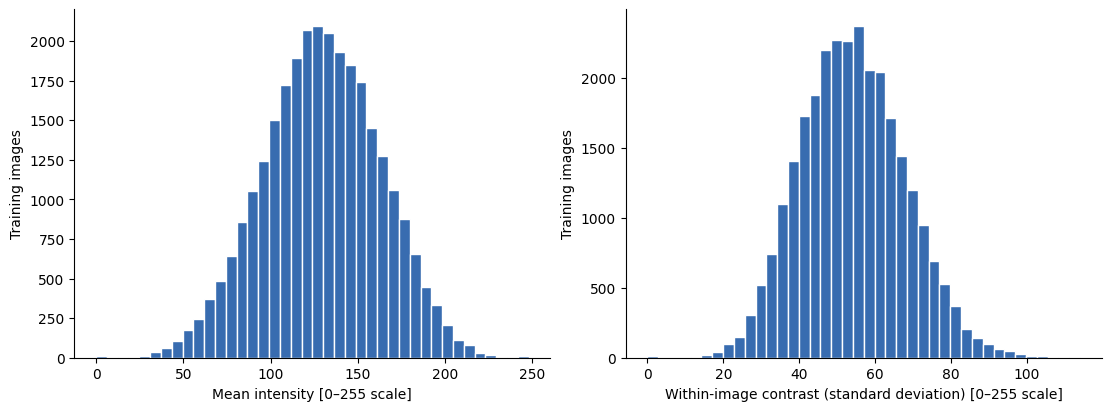

In [6]:
training = [r for r in valid if r['split']=='train']
fig, axes = plt.subplots(1, 2, figsize=(11,4), layout='constrained')
for ax, key, title in zip(axes, ('mean','std'), ('Mean intensity','Within-image contrast (standard deviation)')):
    ax.hist([r[key] for r in training], bins=40, color='#386cb0', edgecolor='white')
    ax.set(xlabel=title+' [0–255 scale]', ylabel='Training images')
    ax.spines[['top','right']].set_visible(False)
fig.savefig(REPORT / 'training_pixel_properties.png', dpi=160)
plt.show()


## 6. Duplicate leakage and conflicting annotations

A duplicate group has at least two members. Redundant files count members beyond one per group.
Cross-split groups span train and test; conflicting groups have more than one folder label. These categories
can overlap. Lists of affected paths stay in ignored local storage, not in notebook outputs.


file_sha256 {
  "groups": 1516,
  "redundant_files": 1853,
  "cross_split_groups": 531,
  "conflicting_label_groups": 57,
  "train_files_overlapping_test": 703
}
pixel_sha256 {
  "groups": 1516,
  "redundant_files": 1853,
  "cross_split_groups": 531,
  "conflicting_label_groups": 57,
  "train_files_overlapping_test": 703
}


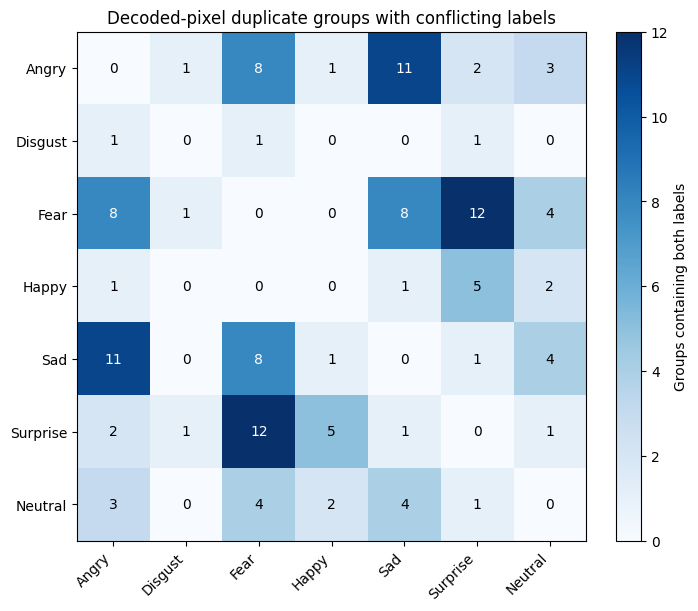

In [7]:
def summarize_duplicates(key):
    buckets = defaultdict(list)
    for record in records:
        if key in record:
            buckets[record[key]].append(record)
    groups = [group for group in buckets.values() if len(group)>1]
    cross = [g for g in groups if len({r['split'] for r in g})>1]
    conflict = [g for g in groups if len({r['label'] for r in g})>1]
    stats = dict(groups=len(groups), redundant_files=sum(len(g)-1 for g in groups),
                 cross_split_groups=len(cross), conflicting_label_groups=len(conflict),
                 train_files_overlapping_test=sum(r['split']=='train' for g in cross for r in g))
    return stats, groups

duplicate_stats, duplicate_members = {}, {}
for key in ('file_sha256', 'pixel_sha256'):
    duplicate_stats[key], duplicate_members[key] = summarize_duplicates(key)
    print(key, json.dumps(duplicate_stats[key], indent=2))

pixel_groups = duplicate_members['pixel_sha256']
conflict_matrix = np.zeros((len(LABELS), len(LABELS)), dtype=int)
for group in pixel_groups:
    ids = sorted({r['model_id'] for r in group})
    for i in ids:
        for j in ids:
            if i != j:
                conflict_matrix[i,j] += 1
fig, ax = plt.subplots(figsize=(7,6), layout='constrained')
heat = ax.imshow(conflict_matrix, cmap='Blues', vmin=0)
ax.set_xticks(range(7), [s.title() for s in LABELS], rotation=45, ha='right')
ax.set_yticks(range(7), [s.title() for s in LABELS])
ax.set_title('Decoded-pixel duplicate groups with conflicting labels')
for i in range(7):
    for j in range(7):
        ax.text(j,i,str(conflict_matrix[i,j]),ha='center',va='center',
                color='white' if conflict_matrix[i,j] > conflict_matrix.max()/2 else 'black')
fig.colorbar(heat, ax=ax, label='Groups containing both labels')
fig.savefig(REPORT / 'label_conflicts.png', dpi=160)
plt.show()


## 7. Findings and training implications

The counts below are computed from this run, not copied from task status notes. Integrity and leakage
findings must be addressed in a later explicit data-preparation step. No images are deleted here.


In [8]:
print('MEASURED FINDINGS')
print(f'{len(records):,} image files; {len(errors):,} failed decoding; modes: {dict(modes)}')
for kind, stats in duplicate_stats.items():
    print(f"{kind}: {stats['cross_split_groups']} cross-split groups; "
          f"{stats['conflicting_label_groups']} conflicting-label groups")
print('NEXT DECISIONS')
print('- Preserve original test membership; exclude matching training content after documenting a policy.')
print('- Review conflicting labels; quarantine unresolved groups instead of silently choosing a label.')
print('- Create seeded, class-stratified validation from eligible training images, grouping duplicates together.')
print('- Publish final split counts/manifests; never fit augmentation/normalization/weights on test data.')
print('- Select models on validation; report held-out accuracy, macro-F1, per-class recall/F1 and confusion matrix.')
print('- Test identity leakage / near duplicates separately; exact hashes do not establish independence.')
print('- Confirm face-crop/input normalization and checkpoint contract when the model is implemented.')


MEASURED FINDINGS
35,887 image files; 0 failed decoding; modes: {'L': 35887}
file_sha256: 531 cross-split groups; 57 conflicting-label groups
pixel_sha256: 531 cross-split groups; 57 conflicting-label groups
NEXT DECISIONS
- Preserve original test membership; exclude matching training content after documenting a policy.
- Review conflicting labels; quarantine unresolved groups instead of silently choosing a label.
- Create seeded, class-stratified validation from eligible training images, grouping duplicates together.
- Publish final split counts/manifests; never fit augmentation/normalization/weights on test data.
- Select models on validation; report held-out accuracy, macro-F1, per-class recall/F1 and confusion matrix.
- Test identity leakage / near duplicates separately; exact hashes do not establish independence.
- Confirm face-crop/input normalization and checkpoint contract when the model is implemented.


## 8. Export reproducible analysis evidence

The small summary records config/notebook/manifest fingerprints, package versions and measured aggregates.
The local CSV contains relative image paths, labels, IDs, hashes and measurements for later review. Exported
records do not assign validation membership or change labels. Aggregate PNGs contain no face samples.


In [9]:
fieldnames = sorted({key for record in records for key in record})
with (LOCAL / 'image_inventory.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=fieldnames)
    writer.writeheader(); writer.writerows(records)
(LOCAL / 'duplicate_groups.json').write_text(json.dumps(duplicate_members, indent=2), encoding='utf-8')
(LOCAL / 'label_mapping.json').write_text(json.dumps(CLASS_TO_ID, indent=2), encoding='utf-8')
import PIL, matplotlib
manifest_text = '\n'.join(f"{r['path']}|{r.get('file_sha256','ERROR')}" for r in records)
notebook_path = ROOT / 'notebooks/emotion_eda.ipynb'
summary = dict(run_id=RUN_ID, source='https://www.kaggle.com/datasets/msambare/fer2013',
    license_metadata='Database: Open Database, Contents: Database Contents',
    license_metadata_checked='2026-11-05', counts=counts, class_to_id=CLASS_TO_ID,
    image_files=len(records), decoded=len(valid), decoding_errors=len(errors),
    unexpected_files=len(ignored), dimensions=dict(dimensions), modes=dict(modes),
    constant_images=sum(r['std']==0 for r in valid), duplicate_stats=duplicate_stats,
    python=platform.python_version(), numpy=np.__version__, pillow=PIL.__version__,
    matplotlib=matplotlib.__version__, seed=SEED,
    config_sha256=hashlib.sha256(CONFIG.read_bytes()).hexdigest(),
    notebook_sha256=hashlib.sha256(notebook_path.read_bytes()).hexdigest(),
    manifest_sha256=hashlib.sha256(manifest_text.encode()).hexdigest(),
    limitations=['Exact bytes/pixels only; no near-duplicate or identity audit.',
                 'No independent visual label review; no split revision or training.'])
(REPORT / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Saved aggregate evidence:', REPORT.relative_to(ROOT))
print('Saved local-only inventories:', LOCAL.relative_to(ROOT))


Saved aggregate evidence: reports\emotion\20261105T163647409557Z
Saved local-only inventories: data\emotion_eda\20261105T163647409557Z


## 9. Dataset revision policy

We manually reviewed 57 groups of identical images with conflicting labels. We marked 6 unclear groups for exclusion and chose one emotion label for each of the other 51 groups. The decisions are saved in `manual_label_review.csv` alongside the local audit files under `data/emotion_eda/`.

We applied these decisions to all copies, including test images. The revised test set contains **10 retained images with changed labels**. Across the original test files, 12 received a revised label; 2 of those copies were removed during deduplication.

The original files will stay unchanged. We will save the revised dataset separately, with a manifest that records each image's original path, original label, revised label, split, and reason for any change or exclusion.

We will keep one copy of each identical image. If an image appears in both training and test data, we will keep it in the test set and exclude its training copies. We will then create a stratified 80/20 training/validation split from the remaining training images, using seed 42.

We will report results as evaluation on a **revised FER2013 test set**. These results are not directly comparable to results on the original test set because we changed labels and removed images. The revised dataset has now been generated under `data/processed/emotion/`. The original dataset remains unchanged.


## 10. Revised dataset and reproducibility

The revised dataset was generated on 6 November 2026 using the saved manual decisions.

| Split | Images |
|---|---:|
| Train | 21,551 |
| Validation | 5,388 |
| Test | 7,089 |
| **Total** | **34,028** |

The 6 excluded groups contained 24 source images. The build also excluded 690 training copies that matched test images and 1,145 other duplicate copies. These counts are separate: images in excluded manual groups are counted only as manual exclusions.

All retained images were copied without re-encoding and checked against the original file hashes. No identical decoded-pixel image appears more than once in the output, so none can cross splits. This check does not cover near duplicates or identity overlap.

**Manual review and reproducibility:** Choosing labels involves human judgment. The decisions are saved in `reports/emotion/review_decisions.csv`, keyed by image content hashes. The script applies those fixed decisions, removes duplicate copies, and creates the validation split with seed 42. The same source files and decision file reproduce the same image selection, labels, and splits. Another reviewer may choose different labels; that would be a different dataset version.

To rebuild into a new directory, run this command from the repository root with the project Python 3.13 environment:

```bash
python scripts/prepare_emotion_data.py --output data/processed/emotion-rebuild
```

The script refuses to overwrite an existing output directory. See `docs/emotion-data.md` for the preparation rules.

The processed directory contains `manifest.csv`, `review_decisions.csv`, `label_mapping.json`, and `summary.json`. The manifest records every original image, its label and split, the revised label, and either its output location or exclusion reason. The summary records settings, counts, and hashes. A small copy of the summary is saved at `reports/emotion/revised_dataset_summary.json`.

Use the processed `train`, `val`, and `test` folders for the next stage. These are results from a **revised FER2013 test set**, with changed labels and removed images, and are not directly comparable to the original benchmark. The earlier notebook outputs describe the original dataset before revision.
